# 09 · Systems for training LLMs: memory, precision, kernels and parallelism

Notebook 08 trained a model; this notebook looks at **what that costs and why**, the part of LLM engineering that decides whether a run fits on your hardware, how fast it goes, and how it scales to many GPUs. Every concept is measured on the course's GPU (an RTX 3060 Laptop, 6 GB):

| question | measured here |
|---|---|
| where does the memory go when training? | weights, gradients, Adam states and activations, each measured and compared with the textbook formulas |
| what do bf16 and activation checkpointing buy? | time, peak memory and loss with and without them |
| why FlashAttention? | naive attention vs PyTorch's fused kernels as the sequence grows, until the naive one runs out of memory |
| where does the time go? | `torch.profiler` on one training step |
| what is kernel launch overhead, and how do CUDA graphs remove it? | eager vs graph-captured forward passes |
| how efficient is the run? | model FLOPs utilization (MFU) against the GPU's measured peak |
| how does training use several GPUs? | real data-parallel training with `DistributedDataParallel` in two processes, and a memory calculator for ZeRO / FSDP at 7B and 70B |

Read it **after notebook 08**.

**Sources.** Stanford CS336 (resource accounting, GPUs, kernels, parallelism); Stanford CME 295 (LLM training); Huyen, *AI Engineering*, ch. 7 and 9 (memory math, inference optimization).

## Background: the arithmetic of training

### Compute

A forward pass costs about $2N$ floating-point operations per token for a model with $N$ parameters (one multiply and one add per weight), and the backward pass about twice that, so training costs

$$C \approx 6\,N\,D \quad \text{FLOPs for } D \text{ tokens}$$

plus an attention term of roughly $12 \, L \, d \, T$ FLOPs per token for $L$ layers of width $d$ and context $T$, which matters only when $T$ is large compared with $d$ (Kaplan et al., 2020; Chowdhery et al., 2022). **Model FLOPs utilization** (MFU) is the share of the hardware's peak FLOP/s that this useful work achieves; well-tuned large runs reach 40–60 %.

### Memory

Training with Adam in mixed precision keeps, per parameter (Rajbhandari et al., 2020, *ZeRO*):

| tensor | bytes per parameter |
|---|---|
| weights used in the forward pass (bf16) | 2 |
| gradients (bf16) | 2 |
| fp32 master weights, Adam's first and second moments | 4 + 4 + 4 = 12 |
| **total** | **16** |

So a 7B-parameter model needs about 112 GB before a single activation, which is why it cannot be trained on one consumer GPU. In plain fp32, as in this notebook's first measurement, it is 4 (weights) + 4 (gradients) + 8 (Adam) = 16 bytes too.

**Activations** are the outputs of every layer kept for the backward pass. They scale with batch × sequence × width × layers, and the attention matrix adds a term in $T^2$ unless the attention kernel avoids storing it. For long sequences and large batches they dominate.

### Tricks that trade one resource for another

- **Mixed precision** (Micikevicius et al., 2018): compute in bf16 or fp16 on tensor cores (several times the fp32 throughput) while keeping fp32 master weights. bf16 has fp32's exponent range, so it needs no loss scaling; fp16 does.
- **Activation checkpointing** (Chen et al., 2016): keep only each block's input and recompute its internals during the backward pass. It costs about one extra forward pass (~30 % more compute) and cuts activation memory to roughly one tensor per block.
- **FlashAttention** (Dao et al., 2022): compute attention in tiles that fit in the GPU's on-chip SRAM, with an online softmax, so the $T \times T$ matrix is never written to slow HBM memory. The result is exact; memory becomes linear in $T$ and speed improves because attention is limited by memory traffic, not arithmetic.
- **Kernel fusion and graph capture**: every PyTorch operation launches a GPU kernel with a fixed overhead of a few microseconds. Small models are dominated by it (notebook 10). `torch.compile` fuses operations into fewer kernels (its default backend generates Triton code); **CUDA graphs** record a sequence of kernels once and replay it with a single launch.

### Arithmetic intensity

Whether an operation is limited by compute or by memory depends on its **arithmetic intensity**, FLOPs per byte moved. A large matrix multiplication does $O(n^3)$ work on $O(n^2)$ data and runs near peak; element-wise operations, normalizations and softmax do $O(1)$ work per byte and are memory-bound. That is why fusing element-wise operations helps, and why FlashAttention's main win is moving fewer bytes.

### Parallelism

| strategy | what is split | communication per step | used for |
|---|---|---|---|
| **data parallel (DDP)** | the batch; every GPU holds the whole model | all-reduce of the gradients | models that fit on one GPU |
| **ZeRO-1 / 2 / 3, FSDP** | optimizer states (1), + gradients (2), + weights (3) across the data-parallel GPUs | reduce-scatter + all-gather | large models without changing the model code |
| **tensor parallel** (Megatron) | each matrix multiplication across GPUs | all-reduce inside every layer | very wide layers, within one node (needs fast links) |
| **pipeline parallel** | the layers, in stages | activations between stages | very deep models across nodes |
| **sequence / context parallel** | the sequence | attention blocks | very long contexts |
| **expert parallel** | the experts of a MoE layer | all-to-all token routing | MoE models (notebook 05) |

Large runs combine them ("3D/4D parallelism"). Data parallelism rests on one fact, checked below: averaging the gradients of $k$ shards of a batch gives exactly the gradient of the whole batch, so $k$ GPUs with batch $b$ train like one GPU with batch $k b$. An **all-reduce** of $P$ bytes with the ring algorithm moves $2 \frac{k-1}{k} P$ bytes per GPU, independent of the number of GPUs.

**Key papers.** Chen et al. (2016), *Training Deep Nets with Sublinear Memory Cost*; Micikevicius et al. (2018), *Mixed Precision Training*; Shoeybi et al. (2019), *Megatron-LM*; Rajbhandari et al. (2020), *ZeRO*; Kaplan et al. (2020), *Scaling Laws for Neural Language Models*; Dao et al. (2022), *FlashAttention*, and Dao (2023), *FlashAttention-2*; Narayanan et al. (2021), *Efficient Large-Scale Language Model Training on GPU Clusters*; Korthikanti et al. (2022), *Reducing Activation Recomputation in Large Transformer Models*; Chowdhery et al. (2022), *PaLM* (MFU); Zhao et al. (2023), *PyTorch FSDP*.

In [1]:
import os, sys, math, time, tempfile
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # notebooks live in notebooks/<topic>/, so climb up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llm_edu_suite` works from the notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llm_edu_suite.utils import seed_everything, get_device, count_params, human, show_mask
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


In [2]:
import gc, logging, subprocess, tempfile, textwrap, random
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)
from llm_edu_suite.model import ModelConfig, TransformerLM
assert device == "cuda", "this notebook measures GPU memory and kernels; it needs a CUDA GPU"
GB = 1024 ** 3
def mem():
    return torch.cuda.memory_allocated() / GB
def reset():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

# The GPU's practical peak: a large bf16 matrix multiplication
a = torch.randn(8192, 8192, device=device, dtype=torch.bfloat16); b = torch.randn(8192, 8192, device=device, dtype=torch.bfloat16)
for _ in range(3): a @ b
torch.cuda.synchronize(); t0 = time.time()
for _ in range(10): a @ b
torch.cuda.synchronize(); PEAK = 2 * 8192 ** 3 * 10 / (time.time() - t0)
del a, b; reset()
print(f"{torch.cuda.get_device_name(0)} | {torch.cuda.get_device_properties(0).total_memory / GB:.1f} GB | measured bf16 matmul peak {PEAK / 1e12:.1f} TFLOP/s")

V, T = 8192, 512
CFG = dict(vocab_size=V, max_seq_len=4096, d_model=512, n_layers=8, n_heads=8, n_kv_heads=8)
def batch(B, T=T, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.randint(0, V, (B, T + 1), generator=g)
    return x[:, :-1].to(device), x[:, 1:].to(device)
N = TransformerLM(ModelConfig(**CFG)).num_params()
print(f"model for the experiments: {N / 1e6:.1f}M parameters (d=512, 8 layers, vocab {V}, context {T})")

NVIDIA GeForce RTX 3060 Laptop GPU | 6.0 GB | measured bf16 matmul peak 23.0 TFLOP/s


model for the experiments: 29.4M parameters (d=512, 8 layers, vocab 8192, context 512)


## 1. Where the memory goes

We move the model to the GPU, run one forward and backward pass, then one optimizer step, and read `torch.cuda.memory_allocated()` after each stage. In fp32 the textbook predicts 4 bytes per parameter for the weights, 4 for the gradients and 8 for Adam's two moments. The **peak** during forward + backward is higher: the activations stored for the backward pass.

              measured  predicted
weights         0.111G     0.110G
grads           0.118G     0.110G
adam            0.219G     0.219G
peak during forward + backward (batch 8 x 512): 1.82 GB, of which activations ~1.71 GB


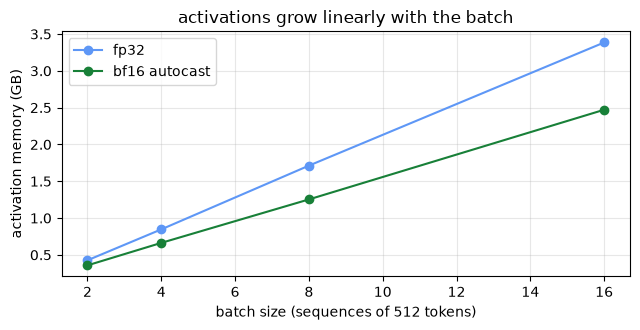

batch  2 fp32: activations 0.43 GB
batch  2 bf16: activations 0.36 GB
batch  4 fp32: activations 0.85 GB
batch  4 bf16: activations 0.66 GB
batch  8 fp32: activations 1.71 GB
batch  8 bf16: activations 1.25 GB
batch 16 fp32: activations 3.39 GB
batch 16 bf16: activations 2.47 GB


In [3]:
def anatomy(B, amp=False):
    reset(); base = mem()
    model = TransformerLM(ModelConfig(**CFG)).to(device); w = mem() - base
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4)
    x, y = batch(B)
    torch.cuda.reset_peak_memory_stats()
    with torch.autocast("cuda", dtype=torch.bfloat16, enabled=amp):
        loss = model(x, y)[1]                               # keep only the loss: holding the logits would distort the measurement
    loss.backward()
    peak_fb = torch.cuda.max_memory_allocated() / GB - base
    g = mem() - base - w
    opt.step(); o = mem() - base - w - g
    del model, opt, x, y, loss; reset()
    return dict(weights=w, grads=g, adam=o, peak=peak_fb, activations=peak_fb - w)

r = anatomy(8)
pred = {"weights": 4 * N / GB, "grads": 4 * N / GB, "adam": 8 * N / GB}
print(f"{'':12s} {'measured':>9s} {'predicted':>10s}")
for k in ("weights", "grads", "adam"):
    print(f"{k:12s} {r[k]:8.3f}G {pred[k]:9.3f}G")
print(f"peak during forward + backward (batch 8 x {T}): {r['peak']:.2f} GB, of which activations ~{r['activations']:.2f} GB")

rows = []
for B in (2, 4, 8, 16):
    for amp in (False, True):
        try:
            rr = anatomy(B, amp); rows.append((B, amp, rr["activations"]))
        except torch.OutOfMemoryError:
            rows.append((B, amp, float("nan"))); reset()
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for amp, c in ((False, "#5e97f6"), (True, "#188038")):
    xs = [B for B, a_, _ in rows if a_ == amp]; ys = [v for B, a_, v in rows if a_ == amp]
    ax.plot(xs, ys, "o-", color=c, label="bf16 autocast" if amp else "fp32")
ax.set_xlabel(f"batch size (sequences of {T} tokens)"); ax.set_ylabel("activation memory (GB)")
ax.set_title("activations grow linearly with the batch"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
for B, amp, v in rows:
    print(f"batch {B:2d} {'bf16' if amp else 'fp32'}: activations {v:.2f} GB")

**What the numbers say.** The textbook arithmetic holds almost to the megabyte: 29.4M fp32 weights take 0.111 GB (predicted 0.110), their gradients 0.118 GB (0.110; the few extra MB are small buffers kept by autograd) and Adam's two moments 0.219 GB (0.219). Together that is the "16 bytes per parameter" rule, 0.45 GB here.

The activations dwarf all of it: at batch 8 the peak during forward and backward is 1.82 GB, about 1.71 GB of activations, and the plot shows them growing linearly with the batch, 0.43 GB at batch 2 to 3.39 GB at batch 16 in fp32. One part of that is easy to forget: the logits, batch × 512 × 8,192 numbers, are kept for the loss. bf16 autocast trims activations by about a quarter (2.47 GB at batch 16) because most saved tensors are half the size; the rest stay in fp32. For a model this size, **activations, not parameters, decide what fits**.

## 2. Mixed precision and activation checkpointing

Same model, batch 8: one training step timed over 10 steps, with fp32 or bf16 autocast, with or without **activation checkpointing**. For checkpointing we wrap every block in `torch.utils.checkpoint.checkpoint`: the block's internal activations are dropped after the forward pass and recomputed during the backward pass. We also run 30 steps of each on the same batches to check that the loss is unaffected.

In [4]:
from torch.utils.checkpoint import checkpoint
class Checkpointed(nn.Module):
    """Wraps a block so its internals are recomputed in the backward pass instead of stored."""
    def __init__(self, block):
        super().__init__(); self.block = block
    def forward(self, x, freqs_cis, start_pos=None):
        return checkpoint(self.block, x, freqs_cis, start_pos, use_reentrant=False)

def run(amp, ckpt, B=8, steps=30, timed=10):
    reset(); seed_everything(0)
    model = TransformerLM(ModelConfig(**CFG)).to(device)
    if ckpt: model.blocks = nn.ModuleList(Checkpointed(b) for b in model.blocks)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4)
    losses, times = [], []
    for s in range(steps):
        x, y = batch(B, seed=s)
        torch.cuda.synchronize(); t0 = time.time()
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=amp):
            _, loss = model(x, y)
        loss.backward(); opt.step(); opt.zero_grad(set_to_none=True)
        torch.cuda.synchronize(); times.append(time.time() - t0); losses.append(loss.item())
    peak = torch.cuda.max_memory_allocated() / GB
    del model, opt; reset()
    return dict(ms=1000 * np.median(times[-timed:]), peak=peak, loss=float(np.mean(losses[-5:])))

TRICKS = {}
for amp in (False, True):
    for ckpt in (False, True):
        name = f"{'bf16' if amp else 'fp32'}{' + checkpointing' if ckpt else ''}"
        TRICKS[name] = run(amp, ckpt)
        r = TRICKS[name]
        print(f"{name:24s} step {r['ms']:6.1f} ms | peak memory {r['peak']:.2f} GB | mean loss of the last 5 steps {r['loss']:.3f}")

fp32                     step  275.6 ms | peak memory 2.18 GB | mean loss of the last 5 steps 9.062


fp32 + checkpointing     step  337.8 ms | peak memory 0.93 GB | mean loss of the last 5 steps 9.062


bf16                     step  123.6 ms | peak memory 1.66 GB | mean loss of the last 5 steps 9.062


bf16 + checkpointing     step  150.9 ms | peak memory 0.81 GB | mean loss of the last 5 steps 9.062


**What the numbers say.**

- **bf16 autocast** makes a step 2.2× faster (275.6 → 123.6 ms) and lowers the peak memory from 2.18 to 1.66 GB. That is the tensor cores at work: this GPU's measured bf16 matmul peak is about 23 TFLOP/s, several times its fp32 throughput.
- **Activation checkpointing** cuts the peak memory by more than half (2.18 → 0.93 GB in fp32, 1.66 → 0.81 GB in bf16) for about 22 % more time per step (123.6 → 150.9 ms in bf16), close to the "one extra forward pass" the theory predicts.
- The loss is the same in all four runs (9.062). The data are random tokens, so this only checks that the numerics agree, not that the model learns.

Absolute step times move between runs on a laptop GPU (power and temperature limits); the ratios are what carry over. In practice the two tricks are combined: bf16 everywhere, and checkpointing when the batch or the sequence does not fit.

## 3. Attention kernels: why FlashAttention

One causal attention layer (8 heads of 64 dimensions, batch 1, bf16), forward and backward, as the sequence grows. The **naive** version is the textbook formula: it materialises the $T \times T$ score matrix, applies the mask and softmax, and multiplies by $V$. `F.scaled_dot_product_attention` (SDPA) dispatches to one of several backends, which we force one at a time:

- **math**: PyTorch's unfused reference implementation (it also materialises the scores);
- **FlashAttention-2**: compiled into the Linux wheels of PyTorch, **but not into the Windows wheels** used on this machine;
- **memory-efficient** (Rabe and Staats, 2021; the xformers kernel) and **cuDNN** fused attention: tiled, IO-aware kernels built on the same idea as FlashAttention, available here.

The cell checks which backends this PyTorch build can run before benchmarking. Knowing which kernel your stack actually uses is part of the job: the same code can be several times slower, or run out of memory, on a build that silently falls back to the unfused path.

SDPA: FlashAttention-2: not available in this PyTorch build


benchmarking: ['naive (materialised T x T)', 'SDPA: math (unfused)', 'SDPA: memory-efficient', 'SDPA: cuDNN']


naive (materialised T x T):
   T=512: 1.0 ms, 0.035 GB | T=1024: 1.8 ms, 0.085 GB | T=2048: 6.9 ms, 0.281 GB | T=4096: 27.1 ms, 1.055 GB | T=8192: 135.3 ms, 4.125 GB | T=16384: out of memory
SDPA: math (unfused):
   T=512: 9.7 ms, 0.053 GB | T=1024: 34.1 ms, 0.153 GB | T=2048: 14.8 ms, 0.539 GB | T=4096: 65.7 ms, 2.063 GB | T=8192: 978.3 ms, 8.110 GB | T=16384: out of memory
SDPA: memory-efficient:
   T=512: 0.6 ms, 0.022 GB | T=1024: 1.6 ms, 0.029 GB | T=2048: 6.7 ms, 0.041 GB | T=4096: 21.9 ms, 0.067 GB | T=8192: 23.3 ms, 0.118 GB | T=16384: 138.5 ms, 0.220 GB
SDPA: cuDNN:
   T=512: 0.5 ms, 0.023 GB | T=1024: 0.6 ms, 0.031 GB | T=2048: 5.6 ms, 0.045 GB | T=4096: 19.1 ms, 0.075 GB | T=8192: 30.1 ms, 0.134 GB | T=16384: 51.9 ms, 0.251 GB


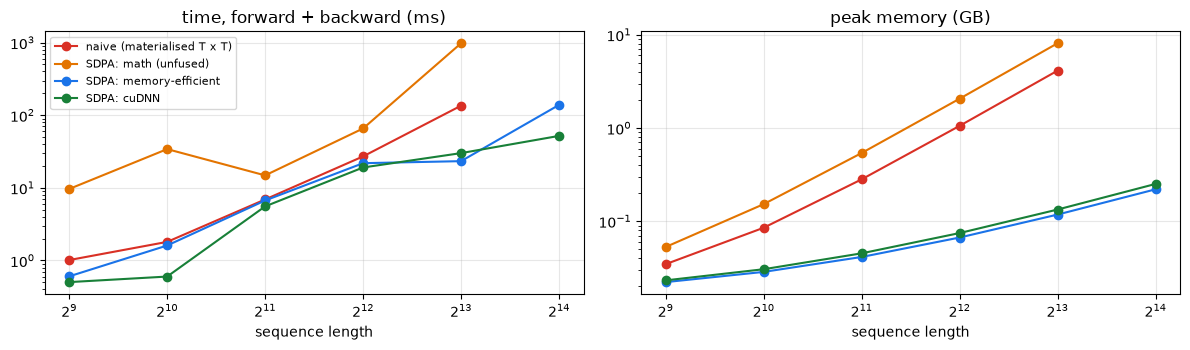

In [5]:
from torch.nn.attention import sdpa_kernel, SDPBackend
def naive_attention(q, k, v):
    Tq = q.shape[-2]
    s = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])
    s = s.masked_fill(torch.triu(torch.ones(Tq, Tq, dtype=torch.bool, device=q.device), 1), float("-inf"))
    return s.softmax(-1) @ v
def sdpa(backend):
    def f(q, k, v):
        with sdpa_kernel(backend):
            return F.scaled_dot_product_attention(q, k, v, is_causal=True)
    return f
import warnings
warnings.filterwarnings("ignore", message=".*(kernel not used|not compiled with flash|runtime disabled).*")
CANDIDATES = {"naive (materialised T x T)": naive_attention, "SDPA: math (unfused)": sdpa(SDPBackend.MATH),
              "SDPA: FlashAttention-2": sdpa(SDPBackend.FLASH_ATTENTION), "SDPA: memory-efficient": sdpa(SDPBackend.EFFICIENT_ATTENTION),
              "SDPA: cuDNN": sdpa(SDPBackend.CUDNN_ATTENTION)}
IMPL = {}
for name, fn in CANDIDATES.items():
    t_ = torch.randn(1, 8, 128, 64, device=device, dtype=torch.bfloat16)
    try:
        fn(t_, t_, t_); IMPL[name] = fn
    except RuntimeError:
        print(f"{name}: not available in this PyTorch build")
del t_
print("benchmarking:", list(IMPL))

def bench(fn, Tlen, H=8, D=64, reps=5):
    reset()
    q, k, v = (torch.randn(1, H, Tlen, D, device=device, dtype=torch.bfloat16, requires_grad=True) for _ in range(3))
    try:
        for _ in range(2): fn(q, k, v).sum().backward()
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t0 = time.time()
        for _ in range(reps): fn(q, k, v).sum().backward()
        torch.cuda.synchronize()
        return 1000 * (time.time() - t0) / reps, torch.cuda.max_memory_allocated() / GB
    except torch.OutOfMemoryError:
        return float("nan"), float("nan")
    finally:
        del q, k, v; reset()

LENGTHS = [512, 1024, 2048, 4096, 8192, 16384]
ATT = {name: [bench(fn, L) for L in LENGTHS] for name, fn in IMPL.items()}
for n in IMPL:
    print(f"{n}:")
    print("   " + " | ".join(f"T={L}: {ms:.1f} ms, {gb:.3f} GB" if ms == ms else f"T={L}: out of memory" for L, (ms, gb) in zip(LENGTHS, ATT[n])))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for n, c in zip(IMPL, ("#d93025", "#e37400", "#1a73e8", "#188038", "#9334e6")):
    ax[0].plot(LENGTHS, [r[0] for r in ATT[n]], "o-", color=c, label=n); ax[1].plot(LENGTHS, [r[1] for r in ATT[n]], "o-", color=c, label=n)
for a_, t_ in ((ax[0], "time, forward + backward (ms)"), (ax[1], "peak memory (GB)")):
    a_.set_xscale("log", base=2); a_.set_yscale("log"); a_.set_xlabel("sequence length"); a_.set_title(t_); a_.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**What the numbers say.** This PyTorch build has no FlashAttention-2 (the Windows wheels are built without it), so the fused kernels compared are the memory-efficient one and cuDNN's.

- **Memory.** The naive implementation stores the $T \times T$ scores, so its memory grows with the square of the sequence: 0.035 GB at 512 tokens, 4.1 GB at 8,192, and out of memory at 16,384. The fused kernels grow linearly: the memory-efficient kernel needs 0.118 GB at 8,192 and 0.220 GB at 16,384, about 35× less than naive at 8,192.
- **Speed.** At 16,384 tokens cuDNN takes 51.9 ms for forward and backward, a length the naive version cannot run at all. At short lengths all are fast and the differences are noise.
- **A Windows trap.** SDPA's unfused *math* backend reported 8.1 GB at 8,192 tokens on a 6 GB card and took 978 ms. Instead of failing, the Windows driver spilled into system RAM ("shared GPU memory"), which avoids the crash but runs many times slower. If a job suddenly slows down instead of crashing, check whether it is paging into shared memory.

This is why every serious LLM codebase uses a fused attention kernel, and why checking which backend your build actually dispatches to belongs in a performance review.

## 4. Profiling a training step

`torch.profiler` records every operator and every GPU kernel of one bf16 training step (batch 8). The table lists the operators that used the most GPU time; below it we add up how much of the GPU time went into matrix multiplications.

In [6]:
from torch.profiler import profile, ProfilerActivity
reset(); seed_everything(0)
model = TransformerLM(ModelConfig(**CFG)).to(device); opt = torch.optim.AdamW(model.parameters(), lr=3e-4)
def step(s=0):
    x, y = batch(8, seed=s)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        _, loss = model(x, y)
    loss.backward(); opt.step(); opt.zero_grad(set_to_none=True)
for s in range(3): step(s)
torch.cuda.synchronize()
with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as prof:
    step(3); torch.cuda.synchronize()
ev = prof.key_averages()
dev_time = lambda e: getattr(e, "self_device_time_total", None) or getattr(e, "self_cuda_time_total", 0)
total = sum(dev_time(e) for e in ev)
top = sorted(ev, key=dev_time, reverse=True)[:10]
print(f"{'operator':45s} {'GPU time':>10s} {'share':>7s} {'calls':>6s}")
for e in top:
    print(f"{e.key[:45]:45s} {dev_time(e) / 1000:8.2f} ms {dev_time(e) / total:6.1%} {e.count:6d}")
mm = sum(dev_time(e) for e in ev if any(k in e.key.lower() for k in ("mm", "gemm", "matmul", "linear")) and not e.key.startswith("aten::linear"))
n_kernels = sum(e.count for e in prof.events() if e.device_type.name == "CUDA")
print(f"\nGPU time in one step: {total / 1000:.1f} ms | matrix multiplications: {mm / total:.0%} | GPU kernels launched: {n_kernels:,}")
del model, opt; reset()

operator                                        GPU time   share  calls
aten::mm                                         53.15 ms  23.4%    171
ampere_bf16_s1688gemm_bf16_128x128_ldg8_f2f_s    16.98 ms   7.5%     49
aten::mul                                        13.51 ms   6.0%    227
aten::copy_                                      12.19 ms   5.4%    333
ampere_bf16_s1688gemm_bf16_128x128_ldg8_f2f_s    11.86 ms   5.2%     41
aten::_efficient_attention_backward               8.21 ms   3.6%      8
_Z52fmha_cutlassB_bf16_aligned_64x64_k64_seqa     8.21 ms   3.6%      8
Optimizer.step#AdamW.step                         7.64 ms   3.4%      1
ampere_bf16_s16816gemm_bf16_64x128_ldg8_f2f_s     7.42 ms   3.3%     16
_ZN2at6native27unrolled_elementwise_kernelIZZ     5.65 ms   2.5%    131

GPU time in one step: 226.9 ms | matrix multiplications: 47% | GPU kernels launched: 1,136


**What the numbers say.** One bf16 training step took 226.9 ms of GPU time and launched 1,136 kernels. Matrix multiplications (`aten::mm` and the `ampere_bf16_…gemm` kernels underneath) account for **47 %** of the GPU time. The rest is spread over element-wise operations (`mul`, `copy_`, the RMSNorm and SwiGLU arithmetic), the fused attention backward (3.6 %) and the AdamW update (3.4 %).

In a well-tuned large-model run, matmuls take most of the time. Here the model is small (width 512), so each matmul is short and the memory-bound element-wise kernels weigh more. Those are what kernel fusion (`torch.compile`, Triton, Liger kernels) targets: fuse the normalization, activation and residual operations into fewer kernels, and you remove both their memory traffic and their launch overhead.

## 5. Launch overhead and CUDA graphs

A small model (6 layers of width 256) running the forward pass on a fixed 64-token input, batch 1, as in decoding: hundreds of tiny kernels, each paying a launch cost. `torch.compile` with its default `inductor` backend would fuse them, but it generates Triton kernels and Triton is not supported on Windows, so we use the `cudagraphs` backend: the first call records every kernel into a CUDA graph, and later calls replay the whole graph with one launch.

In [7]:
reset(); seed_everything(0)
small = TransformerLM(ModelConfig(vocab_size=V, max_seq_len=256, d_model=256, n_layers=6, n_heads=4, n_kv_heads=4)).to(device).eval()
xs = torch.randint(0, V, (1, 64), device=device)
def timed(fn, reps=200):
    with torch.no_grad():
        for _ in range(10): fn(xs)
        torch.cuda.synchronize(); t0 = time.time()
        for _ in range(reps): fn(xs)
        torch.cuda.synchronize()
    return 1000 * (time.time() - t0) / reps
try:
    torch.compile(small, backend="inductor")(xs); INDUCTOR = "available"
except Exception as e:
    INDUCTOR = f"unavailable here ({type(e).__name__})"
graphed = torch.compile(small, backend="cudagraphs")
t_eager, t_graph = timed(small), timed(graphed)
with torch.no_grad():
    same = torch.allclose(small(xs)[0], graphed(xs)[0], atol=1e-4)
print(f"inductor backend: {INDUCTOR}")
print(f"eager {t_eager:.2f} ms per forward | CUDA graph {t_graph:.2f} ms | speed-up {t_eager / t_graph:.1f}x | same output: {same}")
del small, graphed; reset()

D:\Trabajo\proyectos\llm-egineering-suite\llm-engineering-suite\.venv\Lib\site-packages\torch\_inductor\lowering.py:2774: UserWarning: Torchinductor does not support code generation for complex operators. Performance may be worse than eager.
  warnings.warn(


W1109 15:49:34.692000 58752 .venv\Lib\site-packages\torch\_inductor\utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


inductor backend: unavailable here (TritonMissing)
eager 8.68 ms per forward | CUDA graph 2.11 ms | speed-up 4.1x | same output: True


**What the numbers say.** `inductor`, `torch.compile`'s default backend, is unavailable here because Triton is missing on Windows. Capturing the forward pass in a CUDA graph takes it from **8.68 to 2.11 ms, a 4.1× speed-up, with identical output**. The GPU did the same arithmetic; what disappeared is the CPU-side cost of launching each of hundreds of small kernels, which dominated this small model (the caveat of notebook 10). That is why inference servers (vLLM, TensorRT-LLM, llama.cpp) capture the decode step in CUDA graphs. On Linux with Triton, `torch.compile(mode="max-autotune")` would add kernel fusion on top.

## 6. How efficient is the run? Model FLOPs utilization

Throughput of full bf16 training steps at batch 16, converted into useful FLOP/s with $6N + 12 L d T$ FLOPs per token, and divided by the measured peak of the matrix-multiplication benchmark above.

In [8]:
reset(); seed_everything(0)
model = TransformerLM(ModelConfig(**CFG)).to(device); opt = torch.optim.AdamW(model.parameters(), lr=3e-4)
B = 16; times = []
for s in range(15):
    x, y = batch(B, seed=s); torch.cuda.synchronize(); t0 = time.time()
    with torch.autocast("cuda", dtype=torch.bfloat16):
        _, loss = model(x, y)
    loss.backward(); opt.step(); opt.zero_grad(set_to_none=True); torch.cuda.synchronize(); times.append(time.time() - t0)
tok_s = B * T / np.median(times[5:])
flops_per_token = 6 * N + 12 * CFG["n_layers"] * CFG["d_model"] * T
achieved = tok_s * flops_per_token
print(f"{tok_s:,.0f} tokens/s | {flops_per_token / 1e6:.0f} MFLOPs per token | achieved {achieved / 1e12:.2f} TFLOP/s | "
      f"MFU {achieved / PEAK:.0%} of the measured peak ({PEAK / 1e12:.1f} TFLOP/s)")
print(f"at this speed, the {N / 1e6:.0f}M model would need {20 * N / tok_s / 3600:.1f} hours for a Chinchilla-optimal {20 * N / 1e6:.0f}M tokens")
del model, opt; reset()

36,608 tokens/s | 202 MFLOPs per token | achieved 7.38 TFLOP/s | MFU 32% of the measured peak (23.0 TFLOP/s)
at this speed, the 29M model would need 4.5 hours for a Chinchilla-optimal 588M tokens


**What the numbers say.** Training runs at 36,608 tokens/s; at 202 MFLOPs per token that is 7.38 TFLOP/s of useful work, an **MFU of 32 %** of the GPU's measured matmul peak (23.0 TFLOP/s in this run). Large, carefully tuned training runs report 40 to 60 %. For a 29M-parameter model on a laptop, 32 % is reasonable: what is missing is the time spent outside matmuls (section 4) and the launch overhead. The second line puts it in perspective: even this small model would need 4.5 hours of this GPU to see its Chinchilla-optimal 588M tokens.

## 7. Data parallelism for real: two processes, one model

`DistributedDataParallel` (DDP) runs one process per device; each holds a full copy of the model, processes its own shard of the batch, and an **all-reduce** averages the gradients before the optimizer step, so all copies stay identical. We run it for real with two CPU processes and the `gloo` backend (NCCL, the GPU backend, needs Linux and several GPUs), on a small `TransformerLM`, and check the claim behind data parallelism: two processes with batch 4 each must end up with **the same weights** as one process with batch 8.

DDP needs real processes, so the training code is written to a script and launched with `torch.multiprocessing.spawn`, the way a training job is launched. On Windows the processes meet through a shared file (`init_method="file://..."`), since `torchrun`'s TCP rendezvous needs a library this PyTorch build lacks.

In [ ]:
DDP_SCRIPT = r"""
import os, sys, time, torch, torch.distributed as dist, torch.multiprocessing as mp
from torch.nn.parallel import DistributedDataParallel as DDP
sys.path.insert(0, sys.argv[1])
from llm_edu_suite.model import ModelConfig, TransformerLM
CFG = ModelConfig(vocab_size=512, max_seq_len=64, d_model=64, n_layers=2, n_heads=4, n_kv_heads=4)
STEPS, PER_RANK = 5, 4
def data(step, n):
    g = torch.Generator().manual_seed(100 + step)
    x = torch.randint(0, 512, (n, 33), generator=g)
    return x[:, :-1], x[:, 1:]
def worker(rank, world, store, out):
    torch.set_num_threads(1)
    dist.init_process_group("gloo", init_method="file:///" + store, rank=rank, world_size=world)
    torch.manual_seed(0); model = TransformerLM(CFG); ddp = DDP(model)
    opt = torch.optim.SGD(ddp.parameters(), lr=0.1)
    comm = sum(p.numel() for p in model.parameters()) * 4
    t0 = time.time()
    for s in range(STEPS):
        x, y = data(s, PER_RANK * world)
        shard = slice(rank * PER_RANK, (rank + 1) * PER_RANK)
        _, loss = ddp(x[shard], y[shard]); opt.zero_grad(); loss.backward(); opt.step()   # backward triggers the all-reduce
    if rank == 0:
        torch.save({"state": model.state_dict(), "secs": time.time() - t0, "grad_bytes": comm}, out)
    dist.destroy_process_group()
if __name__ == "__main__":
    world, store, out = 2, sys.argv[2], sys.argv[3]
    mp.spawn(worker, args=(world, store, out), nprocs=world)
    torch.manual_seed(0); ref = TransformerLM(CFG); opt = torch.optim.SGD(ref.parameters(), lr=0.1)
    for s in range(STEPS):
        x, y = data(s, PER_RANK * world)
        _, loss = ref(x, y); opt.zero_grad(); loss.backward(); opt.step()
    ddp_state = torch.load(out)
    diff = max((ddp_state["state"][k] - v).abs().max().item() for k, v in ref.state_dict().items())
    print(f"processes: {world} | steps: {STEPS} | batch per process: {PER_RANK} (global {PER_RANK * world})")
    print(f"max |weight difference| DDP vs single process with the global batch: {diff:.2e}")
    print(f"gradient all-reduced per step: {ddp_state['grad_bytes'] / 1e6:.2f} MB; ring all-reduce traffic per process: "
          f"{2 * (world - 1) / world * ddp_state['grad_bytes'] / 1e6:.2f} MB | {ddp_state['secs']:.2f}s for {STEPS} steps")
"""
work = tempfile.mkdtemp()
script = os.path.join(work, "ddp_demo.py")
open(script, "w", encoding="utf-8").write(DDP_SCRIPT)
store, out = os.path.join(work, "store").replace("\\", "/"), os.path.join(work, "rank0.pt")
res = subprocess.run([sys.executable, script, ROOT, store, out], capture_output=True, text=True, timeout=600)
print(res.stdout.strip() or res.stderr[-2000:])

processes: 2 | steps: 5 | batch per process: 4 (global 8)
max |weight difference| DDP vs single process with the global batch: 7.45e-09
gradient all-reduced per step: 0.53 MB; ring all-reduce traffic per process: 0.53 MB | 0.09s for 5 steps


**What the numbers say.** After 5 steps, the weights of the two-process DDP run and of the single process with the global batch differ by at most **7.45 × 10⁻⁹**, which is floating-point rounding. Data parallelism is exactly large-batch training, done by several workers. Each step, every process all-reduced 0.53 MB of gradients (the model's 133k fp32 parameters); with the ring algorithm, each process sends and receives about that much, whatever the number of processes. At scale, that traffic is what fast interconnects (NVLink, InfiniBand) and DDP's overlapping of communication with the backward pass are for.

## 8. Scaling up: memory per GPU with ZeRO and FSDP

What the formulas of the Background mean for real models. Memory per GPU for the model states only (bf16 weights and gradients, fp32 master weights and Adam: $16\Psi$ bytes for $\Psi$ parameters), under data parallelism and the three ZeRO stages (FSDP's "full shard" is ZeRO-3). Activations come on top and are handled with checkpointing and sequence parallelism.

In [10]:
def per_gpu_gb(params, gpus, stage):
    w, g, o = 2 * params, 2 * params, 12 * params          # bf16 weights, bf16 grads, fp32 master + Adam m + v
    if stage == "DDP":      total = w + g + o
    elif stage == "ZeRO-1": total = w + g + o / gpus       # shard optimizer states
    elif stage == "ZeRO-2": total = w + (g + o) / gpus     # + gradients
    else:                   total = (w + g + o) / gpus     # ZeRO-3 / FSDP: + weights
    return total / 1e9
print(f"{'model':>6s} {'GPUs':>5s} " + " ".join(f"{s:>10s}" for s in ("DDP", "ZeRO-1", "ZeRO-2", "ZeRO-3/FSDP")))
for params in (7e9, 70e9):
    for gpus in (8, 64):
        print(f"{params / 1e9:5.0f}B {gpus:5d} " + " ".join(f"{per_gpu_gb(params, gpus, s):8.1f}GB" for s in ("DDP", "ZeRO-1", "ZeRO-2", "ZeRO-3")))

 model  GPUs        DDP     ZeRO-1     ZeRO-2 ZeRO-3/FSDP
    7B     8    112.0GB     38.5GB     26.2GB     14.0GB
    7B    64    112.0GB     29.3GB     15.5GB      1.8GB
   70B     8   1120.0GB    385.0GB    262.5GB    140.0GB
   70B    64   1120.0GB    293.1GB    155.3GB     17.5GB


**What the numbers say.** Plain data parallelism replicates all 16 bytes per parameter on every GPU, so a 7B model needs 112 GB per GPU however many GPUs you add. Sharding is what makes large models trainable:

- **ZeRO-1** shards Adam's states: 38.5 GB per GPU with 8 GPUs.
- **ZeRO-2** also shards the gradients: 26.2 GB.
- **ZeRO-3 / FSDP** also shards the weights: 14.0 GB with 8 GPUs and 1.8 GB with 64.

For 70B the same steps go from 1,120 GB to 140 GB per GPU with 8 GPUs, still too much for an 80 GB H100, and 17.5 GB with 64. ZeRO-3 trades this memory for communication: weights are all-gathered before each layer's forward and backward pass. That is why tensor parallelism inside a node, with fast NVLink, is combined with FSDP across nodes for the largest models.

## Results

| question | measured on an RTX 3060 Laptop (6 GB) | lesson |
|---|---|---|
| model memory, 29.4M params, fp32 + Adam | weights 0.111 GB, gradients 0.118 GB, Adam 0.219 GB (predicted 0.110 / 0.110 / 0.219) | the 16-bytes-per-parameter rule is exact |
| activations | 0.43 → 3.39 GB from batch 2 to 16 (fp32); 1.71 GB at batch 8 vs 0.45 GB of model states | activations decide what fits |
| bf16 autocast | 2.2× faster per step, peak 2.18 → 1.66 GB | always on, with fp32 master weights |
| activation checkpointing | peak memory −57 % (fp32) / −51 % (bf16) for ~22 % more time | the standard trade when memory is the limit |
| attention kernels | naive: 4.1 GB at 8k, out of memory at 16k; fused: 0.22 GB at 16k, 51.9 ms (cuDNN) | fused, IO-aware kernels make long contexts possible; FlashAttention-2 is missing from the Windows wheels |
| profile of one step | 47 % of GPU time in matmuls, 1,136 kernels | small models are dominated by element-wise ops and launches |
| CUDA graphs | 8.68 → 2.11 ms per forward (4.1×), same output | launch overhead is real and removable |
| efficiency | 36,608 tokens/s, 7.38 TFLOP/s, MFU 32 % | a reasonable baseline; large runs reach 40–60 % |
| data parallelism (2 processes) | weights identical to single-process large batch (7.45e-9) | DDP = large-batch training, plus an all-reduce |
| ZeRO / FSDP calculator | 7B: 112 GB (DDP) → 14 GB/GPU (FSDP, 8 GPUs); 70B: 140 GB with 8, 17.5 GB with 64 | sharding is what makes large models trainable |

## In production

**Defaults for a training job.**
- bf16 mixed precision with fp32 master weights.
- A fused attention kernel. Check the backend: on Linux SDPA dispatches to FlashAttention-2/3, and the `flash-attn` package adds more.
- AdamW with weight decay, gradient clipping, and activation checkpointing only where memory forces it.
- Size the batch to fill memory, then use gradient accumulation for the effective batch you want.

**Scaling out.**
- Use DDP while the model's 16 bytes per parameter fit on one GPU.
- Use FSDP (PyTorch's `fully_shard`) or DeepSpeed ZeRO-3 when they do not.
- Add tensor parallelism inside a node for the largest models.
- Reference stacks: `torchtitan` (PyTorch's own, FSDP2 + TP + PP + `torch.compile`), Megatron-LM / NeMo, DeepSpeed. Launch with `torchrun` on Linux, with NCCL over NVLink or InfiniBand.

**Measure before optimizing.**
- Profile a few steps (`torch.profiler`, Nsight Systems).
- Compute MFU from $6N$ FLOPs per token against the GPU's real peak.
- Track tokens per second and memory per GPU on a dashboard. A drop in MFU after a code change is a regression like any other.

**Failure modes.**
- Out of memory from activations, not parameters, which shows up when the sequence length or the batch grows.
- Silent fallbacks: no FlashAttention in the build, or Windows paging GPU memory into system RAM. Both show up as sudden slowdowns.
- fp16 without loss scaling: underflowing gradients.
- Communication-bound scaling: adding GPUs does not speed up the job, because the interconnect cannot keep up with ZeRO-3's all-gathers.
- Nondeterminism between runs from GPU kernels, which matters when comparing small differences.

**Next:** `10_inference_serving.ipynb`, where the same ideas (memory-bound decoding, KV-cache, batching) apply to serving.